# DATASET GENERATION

In [2]:
import pandas as pd
import numpy as np


np.random.seed(42)
n_samples = 200

# 1. Genomic Presence/Absence (10 dummy genes)
genes = [f'gene_{i}' for i in range(1, 11)]
genomic_data = np.random.randint(0, 2, size=(n_samples, len(genes)))

# 2. Nutrients: Iron (continuous) and Carbon Source (categorical)
iron_conc = np.random.uniform(0.1, 10.0, size=n_samples)
carbon_sources = np.random.choice(['glucose', 'fructose', 'acetate'], size=n_samples)

# 3. Suppression Score 
# Logic: Higher iron + glucose = higher suppression
suppression_score = (0.05 * iron_conc) + (0.3 * (carbon_sources == 'glucose')) + np.random.normal(0, 0.05, n_samples)
suppression_score = np.clip(suppression_score, 0, 1) 

# Assemble and Save
df_microbe = pd.DataFrame(genomic_data, columns=genes)
df_microbe['iron_concentration'] = iron_conc
df_microbe['carbon_source'] = carbon_sources
df_microbe['suppression_score'] = suppression_score

df_microbe.to_csv('microbial_suppression_data.csv', index=False)
print("File saved as: microbial_suppression_data.csv")

File saved as: microbial_suppression_data.csv


# IMPORTS AND DATASET LOADING

In [3]:
import numpy as np
import pandas as pd
import os 

path=r'C:\Users\Pratham Shah\Downloads'
os.chdir(path)
df=pd.read_csv('microbial_suppression_data.csv')
print(df)

import xgboost as xgb
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

print(df.head())





     gene_1  gene_2  gene_3  gene_4  gene_5  gene_6  gene_7  gene_8  gene_9  \
0         0       1       0       0       0       1       0       0       0   
1         0       0       0       0       1       0       1       1       1   
2         1       0       1       1       1       1       1       1       1   
3         0       0       1       1       1       0       1       0       0   
4         0       0       1       1       1       1       1       0       1   
..      ...     ...     ...     ...     ...     ...     ...     ...     ...   
195       1       0       0       1       0       0       1       0       0   
196       1       0       1       1       0       0       0       1       0   
197       0       0       0       1       1       0       0       0       0   
198       0       1       1       0       1       1       1       1       0   
199       1       0       0       0       0       0       1       0       0   

     gene_10  iron_concentration carbon_source  sup

# FORMATTING

In [4]:
# 1. Separate features and target
X = df.drop('suppression_score', axis=1).copy()
y = df['suppression_score'].copy()

# 2. One-hot encode the categorical column
# Setting dtype=int 
X = pd.get_dummies(X, columns=['carbon_source'], dtype=int)


print("Encoded Columns:", X.columns.tolist())
display(X.head())

# 4. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Encoded Columns: ['gene_1', 'gene_2', 'gene_3', 'gene_4', 'gene_5', 'gene_6', 'gene_7', 'gene_8', 'gene_9', 'gene_10', 'iron_concentration', 'carbon_source_acetate', 'carbon_source_fructose', 'carbon_source_glucose']


,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,gene_10,iron_concentration,carbon_source_acetate,carbon_source_fructose,carbon_source_glucose
0,0,1,0,0,0,1,0,0,0,1,1.932816,0,0,1
1,0,0,0,0,1,0,1,1,1,0,5.464819,1,0,0
2,1,0,1,1,1,1,1,1,1,1,8.742164,0,0,1
3,0,0,1,1,1,0,1,0,0,0,7.349026,1,0,0
4,0,0,1,1,1,1,1,0,1,1,8.084955,0,0,1


# HYPERPARAMETER TUNING

In [5]:
param_grid={
    'max_depth': [3,4,5],
    'learning_rate': [0.1,0.01,0.001],
    'gamma': [0,0.25],
    'lambda': [1,5] #L2 regularisation to precvent overfitting
}

grid_search=GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    verbose=2,
    cv=3,
    n_jobs=-1
)

# 3. Run the search
grid_search.fit(X_train, y_train)

# 4. Print the winners!
print("Best parameters found: ", grid_search.best_params_)


Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best parameters found:  {'gamma': 0, 'lambda': 5, 'learning_rate': 0.1, 'max_depth': 3}


In [6]:
param_grid2={
    'max_depth': [2,3,4],
    'learning_rate': [0.05,0.1,0.2,0.3],
    'gamma': [0,0.25],
    'lambda': [1,5] #L2 regularisation to precvent overfitting
}

grid_search2=GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid2,
    scoring='neg_mean_squared_error',
    verbose=2,
    cv=3,
    n_jobs=-1
)

# 3. Run the search
grid_search2.fit(X_train, y_train)


print("New Best parameters found: ", grid_search2.best_params_)


Fitting 3 folds for each of 48 candidates, totalling 144 fits
New Best parameters found:  {'gamma': 0, 'lambda': 1, 'learning_rate': 0.05, 'max_depth': 3}


In [7]:
param_grid3 = {
    'max_depth': [3],                 
    'learning_rate': [0.01, 0.03, 0.05, 0.07], # Testing below and slightly above 0.05
    'gamma': [0],                     
    'reg_lambda': [0.1, 0.5, 1, 2]    # Testing below and slightly above 1
}

grid_search3 = GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', seed=42),
    param_grid=param_grid3,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search3.fit(X_train, y_train)
print("Final Cycle Best Params:", grid_search3.best_params_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Final Cycle Best Params: {'gamma': 0, 'learning_rate': 0.05, 'max_depth': 3, 'reg_lambda': 2}


# FINAL MODEL

In [8]:
reg_xgb_final = xgb.XGBRegressor(
    objective='reg:squarederror',
    seed=42,
    **grid_search3.best_params_,
    early_stopping_rounds=10,
    eval_metric='rmse'
)

reg_xgb_final.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=True
)

# Print the best tree number (iteration)
print(f"Best Iteration: {reg_xgb_final.best_iteration}")

# Print the best score achieved
print(f"Best Score: {reg_xgb_final.best_score}")


[0]	validation_0-rmse:0.21601
[1]	validation_0-rmse:0.20746
[2]	validation_0-rmse:0.19918
[3]	validation_0-rmse:0.19132
[4]	validation_0-rmse:0.18416
[5]	validation_0-rmse:0.17742
[6]	validation_0-rmse:0.17089
[7]	validation_0-rmse:0.16483
[8]	validation_0-rmse:0.15871
[9]	validation_0-rmse:0.15332
[10]	validation_0-rmse:0.14802
[11]	validation_0-rmse:0.14312
[12]	validation_0-rmse:0.13814
[13]	validation_0-rmse:0.13362
[14]	validation_0-rmse:0.12925
[15]	validation_0-rmse:0.12523
[16]	validation_0-rmse:0.12123
[17]	validation_0-rmse:0.11745
[18]	validation_0-rmse:0.11378
[19]	validation_0-rmse:0.11052
[20]	validation_0-rmse:0.10724
[21]	validation_0-rmse:0.10422
[22]	validation_0-rmse:0.10146
[23]	validation_0-rmse:0.09871
[24]	validation_0-rmse:0.09631
[25]	validation_0-rmse:0.09386
[26]	validation_0-rmse:0.09177
[27]	validation_0-rmse:0.08964
[28]	validation_0-rmse:0.08763
[29]	validation_0-rmse:0.08568
[30]	validation_0-rmse:0.08403
[31]	validation_0-rmse:0.08248
[32]	validation_0-

# EVALUATION

R2 Score: 0.9160
Mean Absolute Error: 0.0532
     gene_1  gene_2  gene_3  gene_4  gene_5  gene_6  gene_7  gene_8  gene_9  \
95        0       1       0       1       0       0       1       0       1   
15        0       0       0       0       0       1       0       1       0   
30        0       0       0       1       1       0       1       1       1   
158       1       1       0       1       1       1       0       0       0   
128       1       0       0       0       0       1       1       1       1   
115       0       0       1       1       1       0       1       0       1   
69        1       1       0       1       1       1       0       1       1   
170       0       1       0       0       0       1       0       1       1   
174       1       1       1       0       1       1       1       0       0   
45        1       1       1       1       0       0       1       1       0   
66        1       0       0       1       0       0       1       1       0   
182    

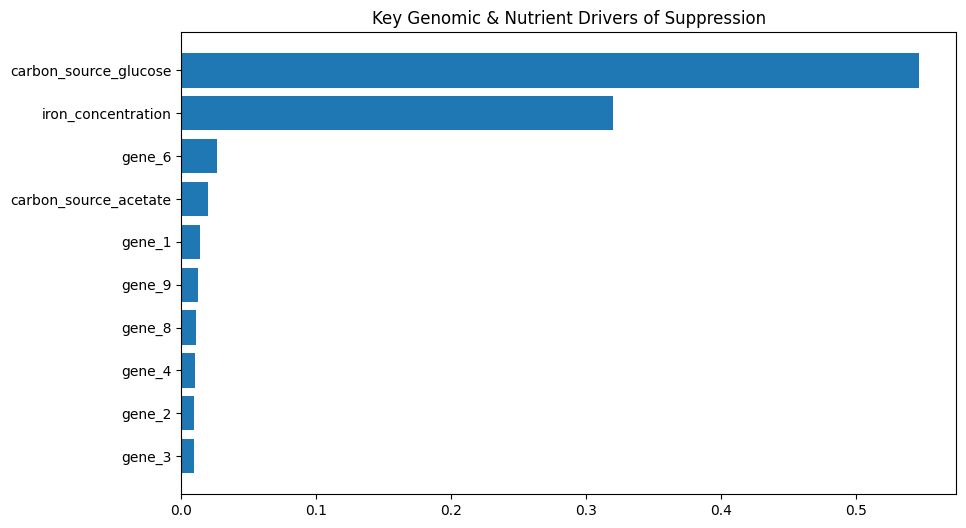

In [10]:
predictions = reg_xgb_final.predict(X_test)
print(f"R2 Score: {r2_score(y_test, predictions):.4f}") 
print(f"Mean Absolute Error: {np.mean(np.abs(y_test - predictions)):.4f}")
print(X_test)
print(y_test)
print(predictions)


importances = reg_xgb_final.feature_importances_
feat_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feat_df['Feature'][:10], feat_df['Importance'][:10])
plt.title("Key Genomic & Nutrient Drivers of Suppression")
plt.gca().invert_yaxis()
plt.show()